
## Derivative — Numerical Methods GFD

In [1]:
clc; clear; close all;

## Exercise 1.1 (a) — First derivative

In [2]:

% (α)
function [du_f, du_b, du_c] = du(h)

    x = 0:h:2;
    u = exp(x).*sin(x);

    i = round(1/h) + 1;

    % Forward
    du_f = (u(i+1) - u(i))/h;

    % Backward
    du_b = (u(i) - u(i-1))/h;

    % Centered
    du_c = (u(i+1) - u(i-1))/(2*h);

end

for h = [0.2, 0.1, 0.05, 0.025]

    [du_f, du_b, du_c] = du(h);

    fprintf('\nFor h = %.3f\n', h);
    fprintf('Forward Difference:  %.2f\n', du_f);
    fprintf('Backward Difference: %.2f\n', du_b);
    fprintf('Centered Difference: %.2f\n', du_c);

end

For h = 0.200
Forward Difference:  4.04
Backward Difference: 3.45
Centered Difference: 3.74
For h = 0.100
Forward Difference:  3.90
Backward Difference: 3.61
Centered Difference: 3.75
For h = 0.050
Forward Difference:  3.83
Backward Difference: 3.68
Centered Difference: 3.76
For h = 0.025
Forward Difference:  3.79
Backward Difference: 3.72
Centered Difference: 3.76



## Exercise 1.1 (b) — Absolute errors

In [3]:

df_1 = exp(1)*(sin(1) + cos(1));

[Df1, Db1, Dc1] = du(0.1);
[Df2, Db2, Dc2] = du(0.2);

fprintf('\nh = 0.1\n');

h = 0.1

In [4]:
E = ET(0.1);
fprintf('Eforward:  %.6f\n', E(1));

Eforward:  0.143747

In [5]:
fprintf('Ebackward: %.6f\n', E(2));

Ebackward: 0.149229

In [6]:
fprintf('Ecentered: %.6f\n', E(3));

Ecentered: 0.002741

In [7]:

fprintf('\nh = 0.2\n');

h = 0.2

In [8]:
E = ET(0.2);
fprintf('Eforward:  %.6f\n', E(1));

Eforward:  0.279568

In [9]:
fprintf('Ebackward: %.6f\n', E(2));

Ebackward: 0.301799

In [10]:
fprintf('Ecentered: %.6f\n', E(3));

Ecentered: 0.011116

In [11]:

function E = ET(h)

    df_1 = exp(1)*(sin(1) + cos(1));

    [Df, Db, Dc] = du(h);

    E = abs([Df, Db, Dc] - df_1);

end


## Exercise 1.1 (c) — Convergence order

In [12]:
% (γ)
fprintf('\nΤάξη σύγκλισης για κάθε μέθοδο\n');

Τάξη σύγκλισης για κάθε μέθοδο

In [13]:

E1 = ET(0.2);
E2 = ET(0.1);

fprintf('Forward  p = %.6f\n', log2(E1(1)/E2(1)));

Forward  p = 0.959671

In [14]:
fprintf('Backward p = %.6f\n', log2(E1(2)/E2(2)));

Backward p = 1.016059

In [15]:
fprintf('Centered  p = %.6f\n', log2(E1(3)/E2(3)));

Centered  p = 2.019622



## Exercise 1.1 (d) — Error plots


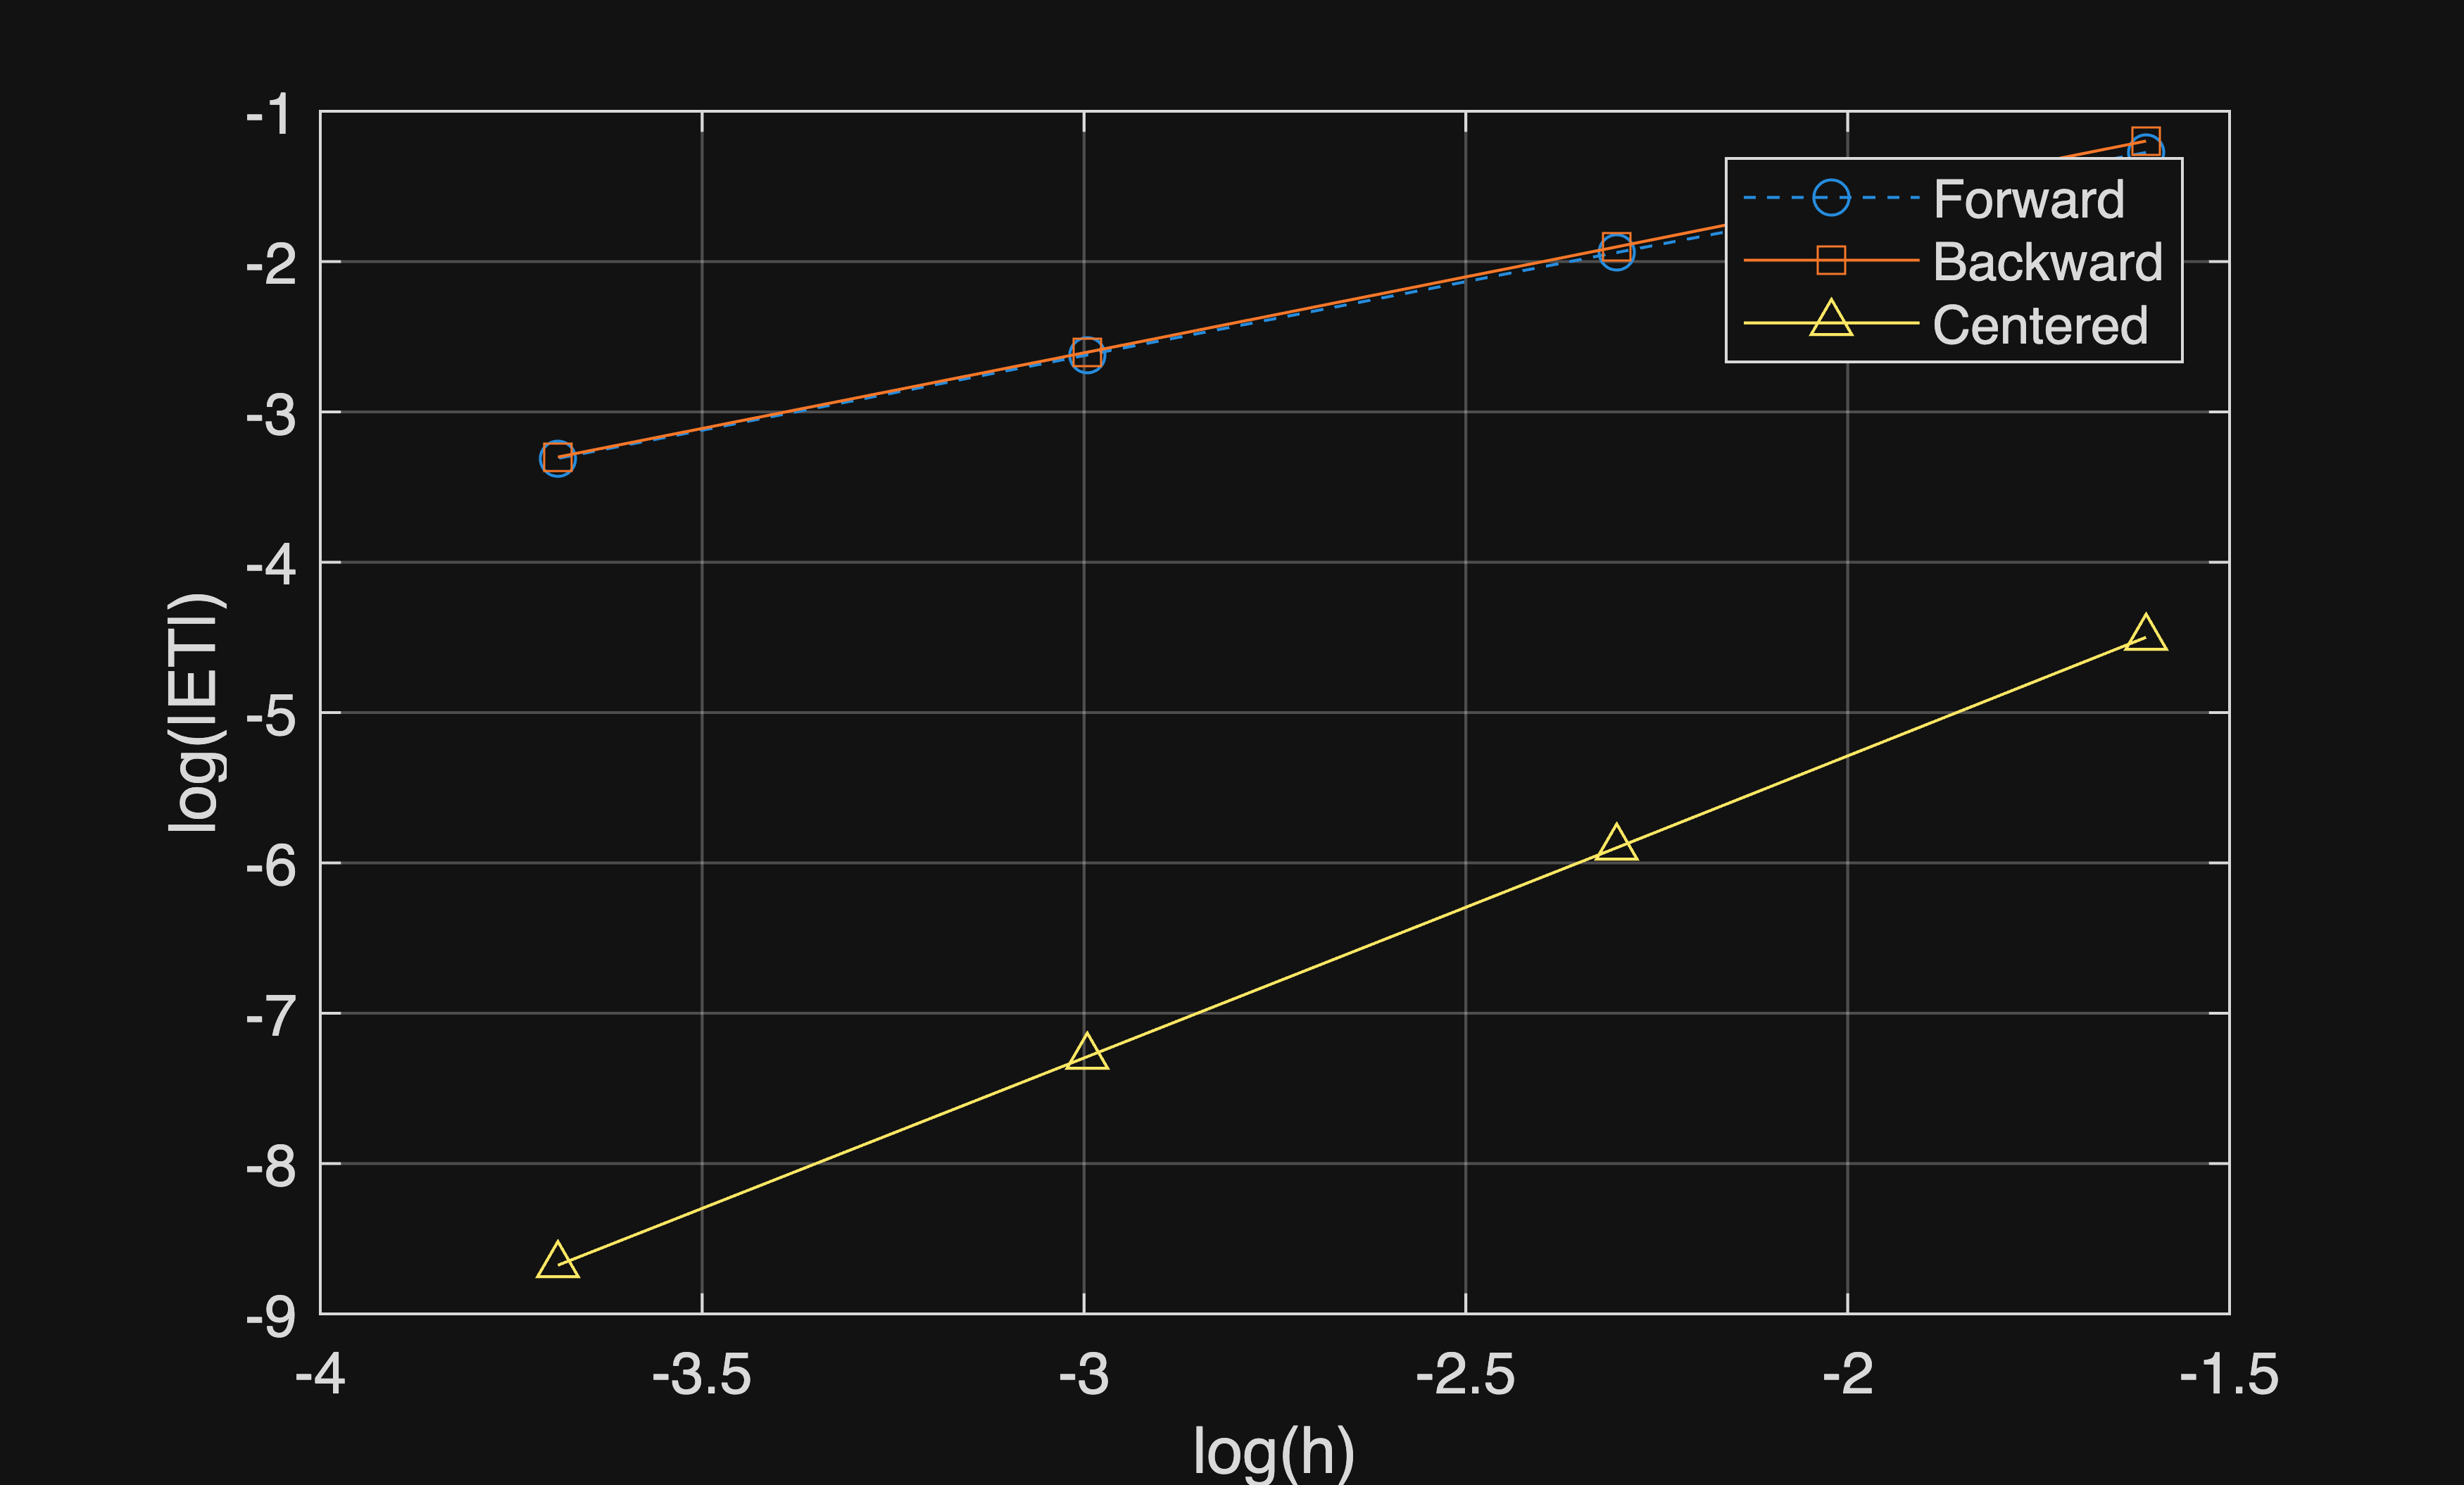

In [16]:

h = [0.2, 0.1, 0.05, 0.025];

E = zeros(length(h), 3);

for j = 1:length(h)
    E(j,:) = ET(h(j));
end

EF = E(:,1);
EB = E(:,2);
EC = E(:,3);

plot(log(h), log(EF), 'o--', 'DisplayName', 'Forward');
hold on
plot(log(h), log(EB), 's-', 'DisplayName', 'Backward');
plot(log(h), log(EC), '^-', 'DisplayName', 'Centered');

legend
xlabel('log(h)')
ylabel('log(|ET|)')
grid on
hold off


## Exercise 1.2 (a) — Second derivative


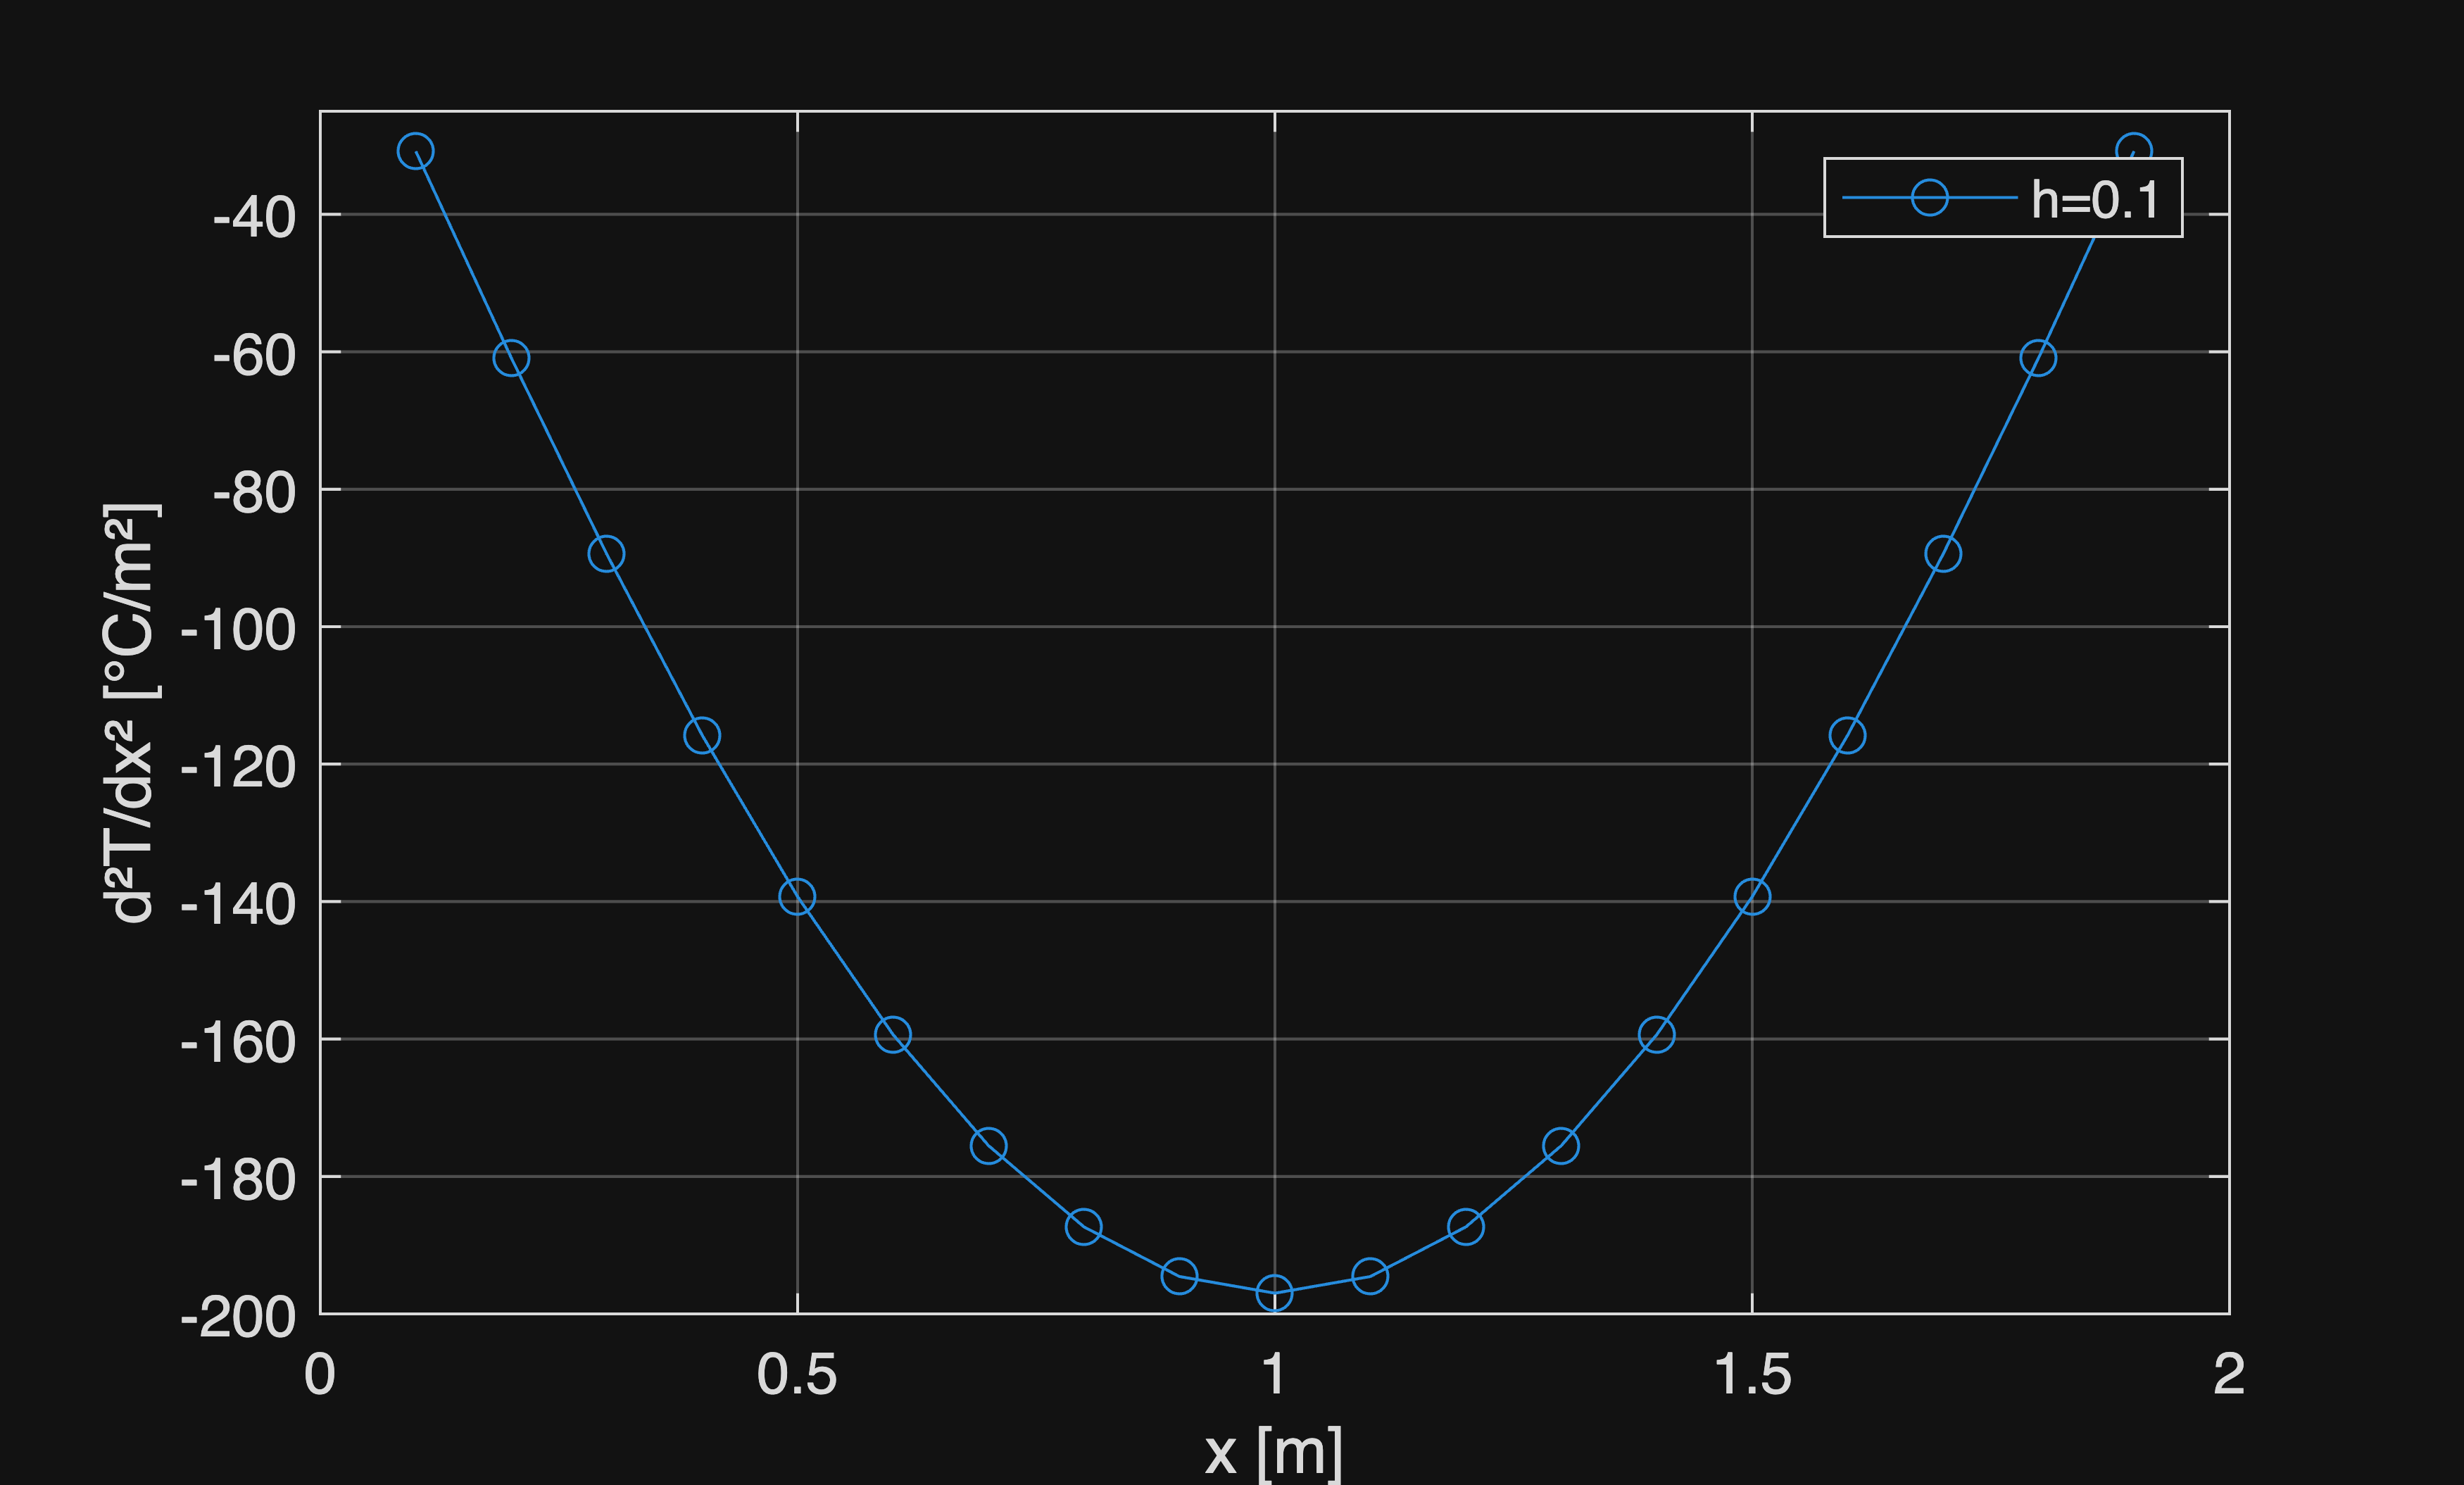

In [17]:

% (α)
h = 0.1;
L = 2;  % m

x = 0:h:L;
T = 20 + 80*sin(pi*x/L);

% Centered Difference - Second derivative
i = 2:length(T)-1;
dT2 = (T(i-1) - 2*T(i) + T(i+1))/h^2;

figure
plot(x(i), dT2, 'o-', 'DisplayName', 'h=0.1');

grid on
legend
xlabel('x [m]')
ylabel('d²T/dx² [°C/m²]')
xlim([0 2])
ylim([-200 -25])


## Exercise 1.2 (b) — Heat\-equation rate


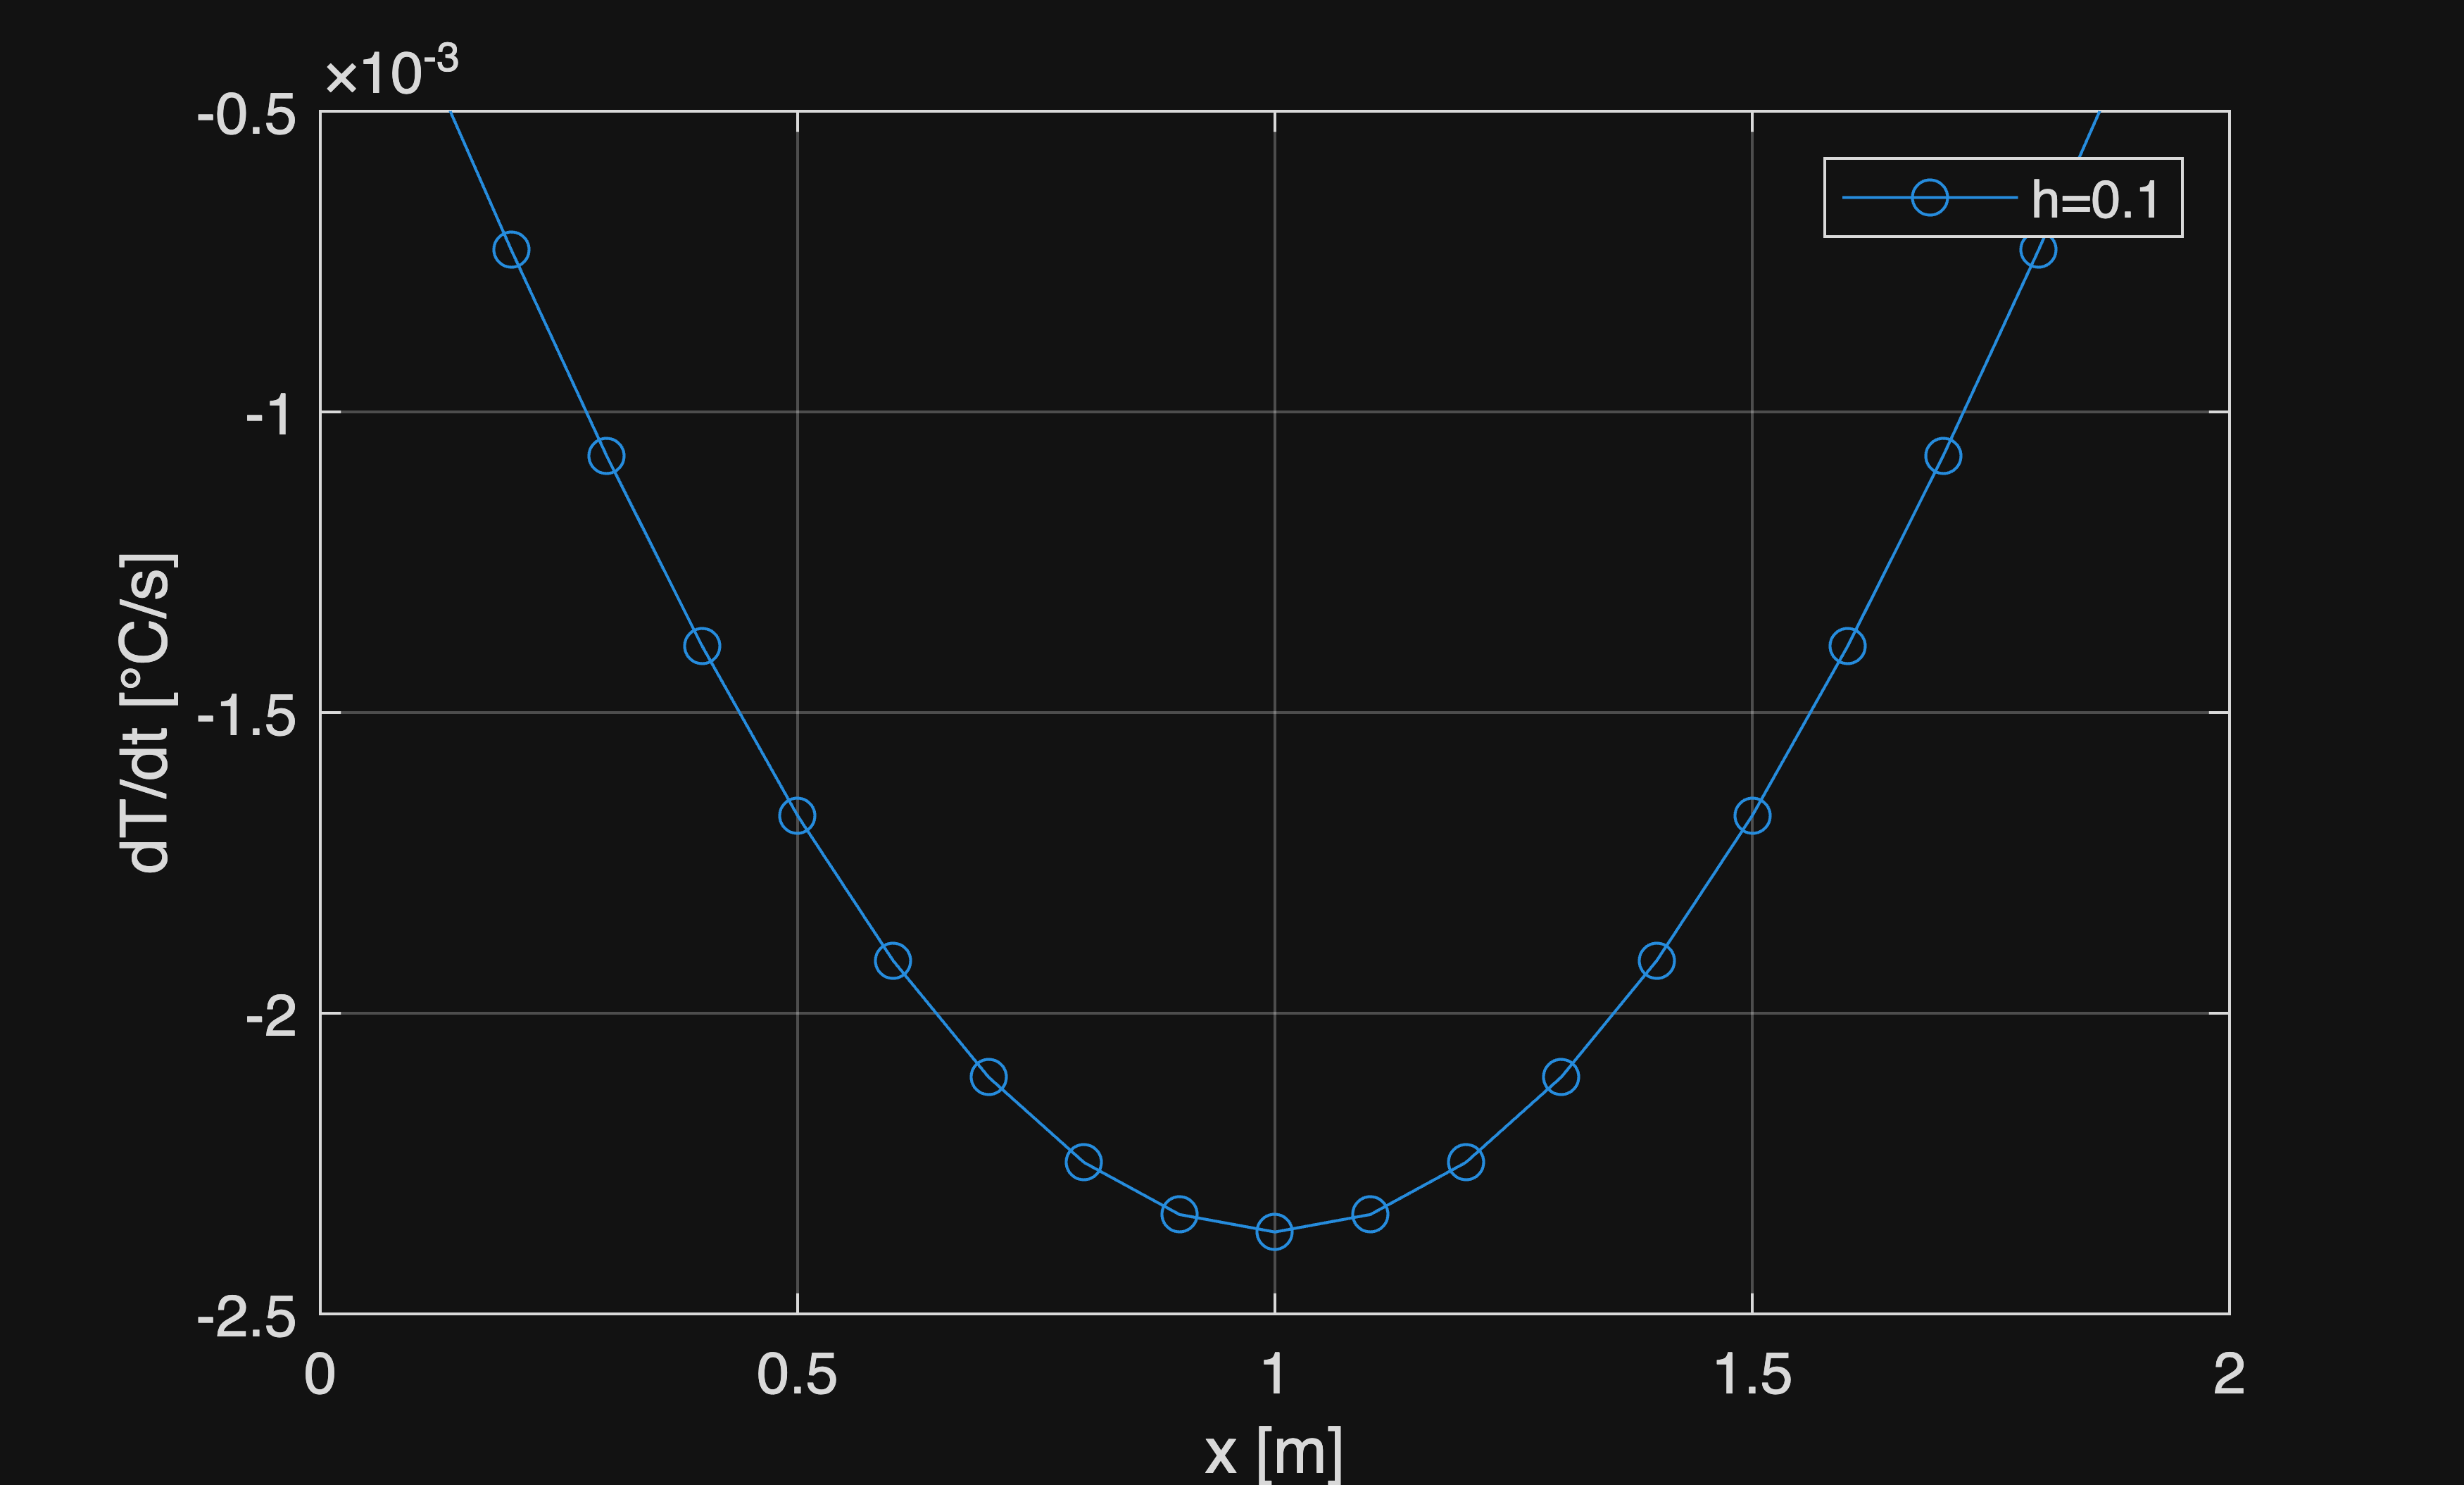

In [18]:

% (β)
a = 1.2e-5;  % m²/s
dT = a*dT2;

figure
plot(x(i), dT, 'o-', 'DisplayName', 'h=0.1');

grid on
legend
xlabel('x [m]')
ylabel('dT/dt [°C/s]')
xlim([0 2])
ylim([-0.0025 -0.0005])

In [19]:

[dTmin, j] = min(dT);

fprintf('Η θερμοκρασία μειώνεται με ρυθμό %.6f °C/s στο x = %.2f m\n', ...
    dTmin, x(i(j)));

Η θερμοκρασία μειώνεται με ρυθμό -0.002364 °C/s στο x = 1.00 m



## Exercise 1.2 (c) — Analytical comparison


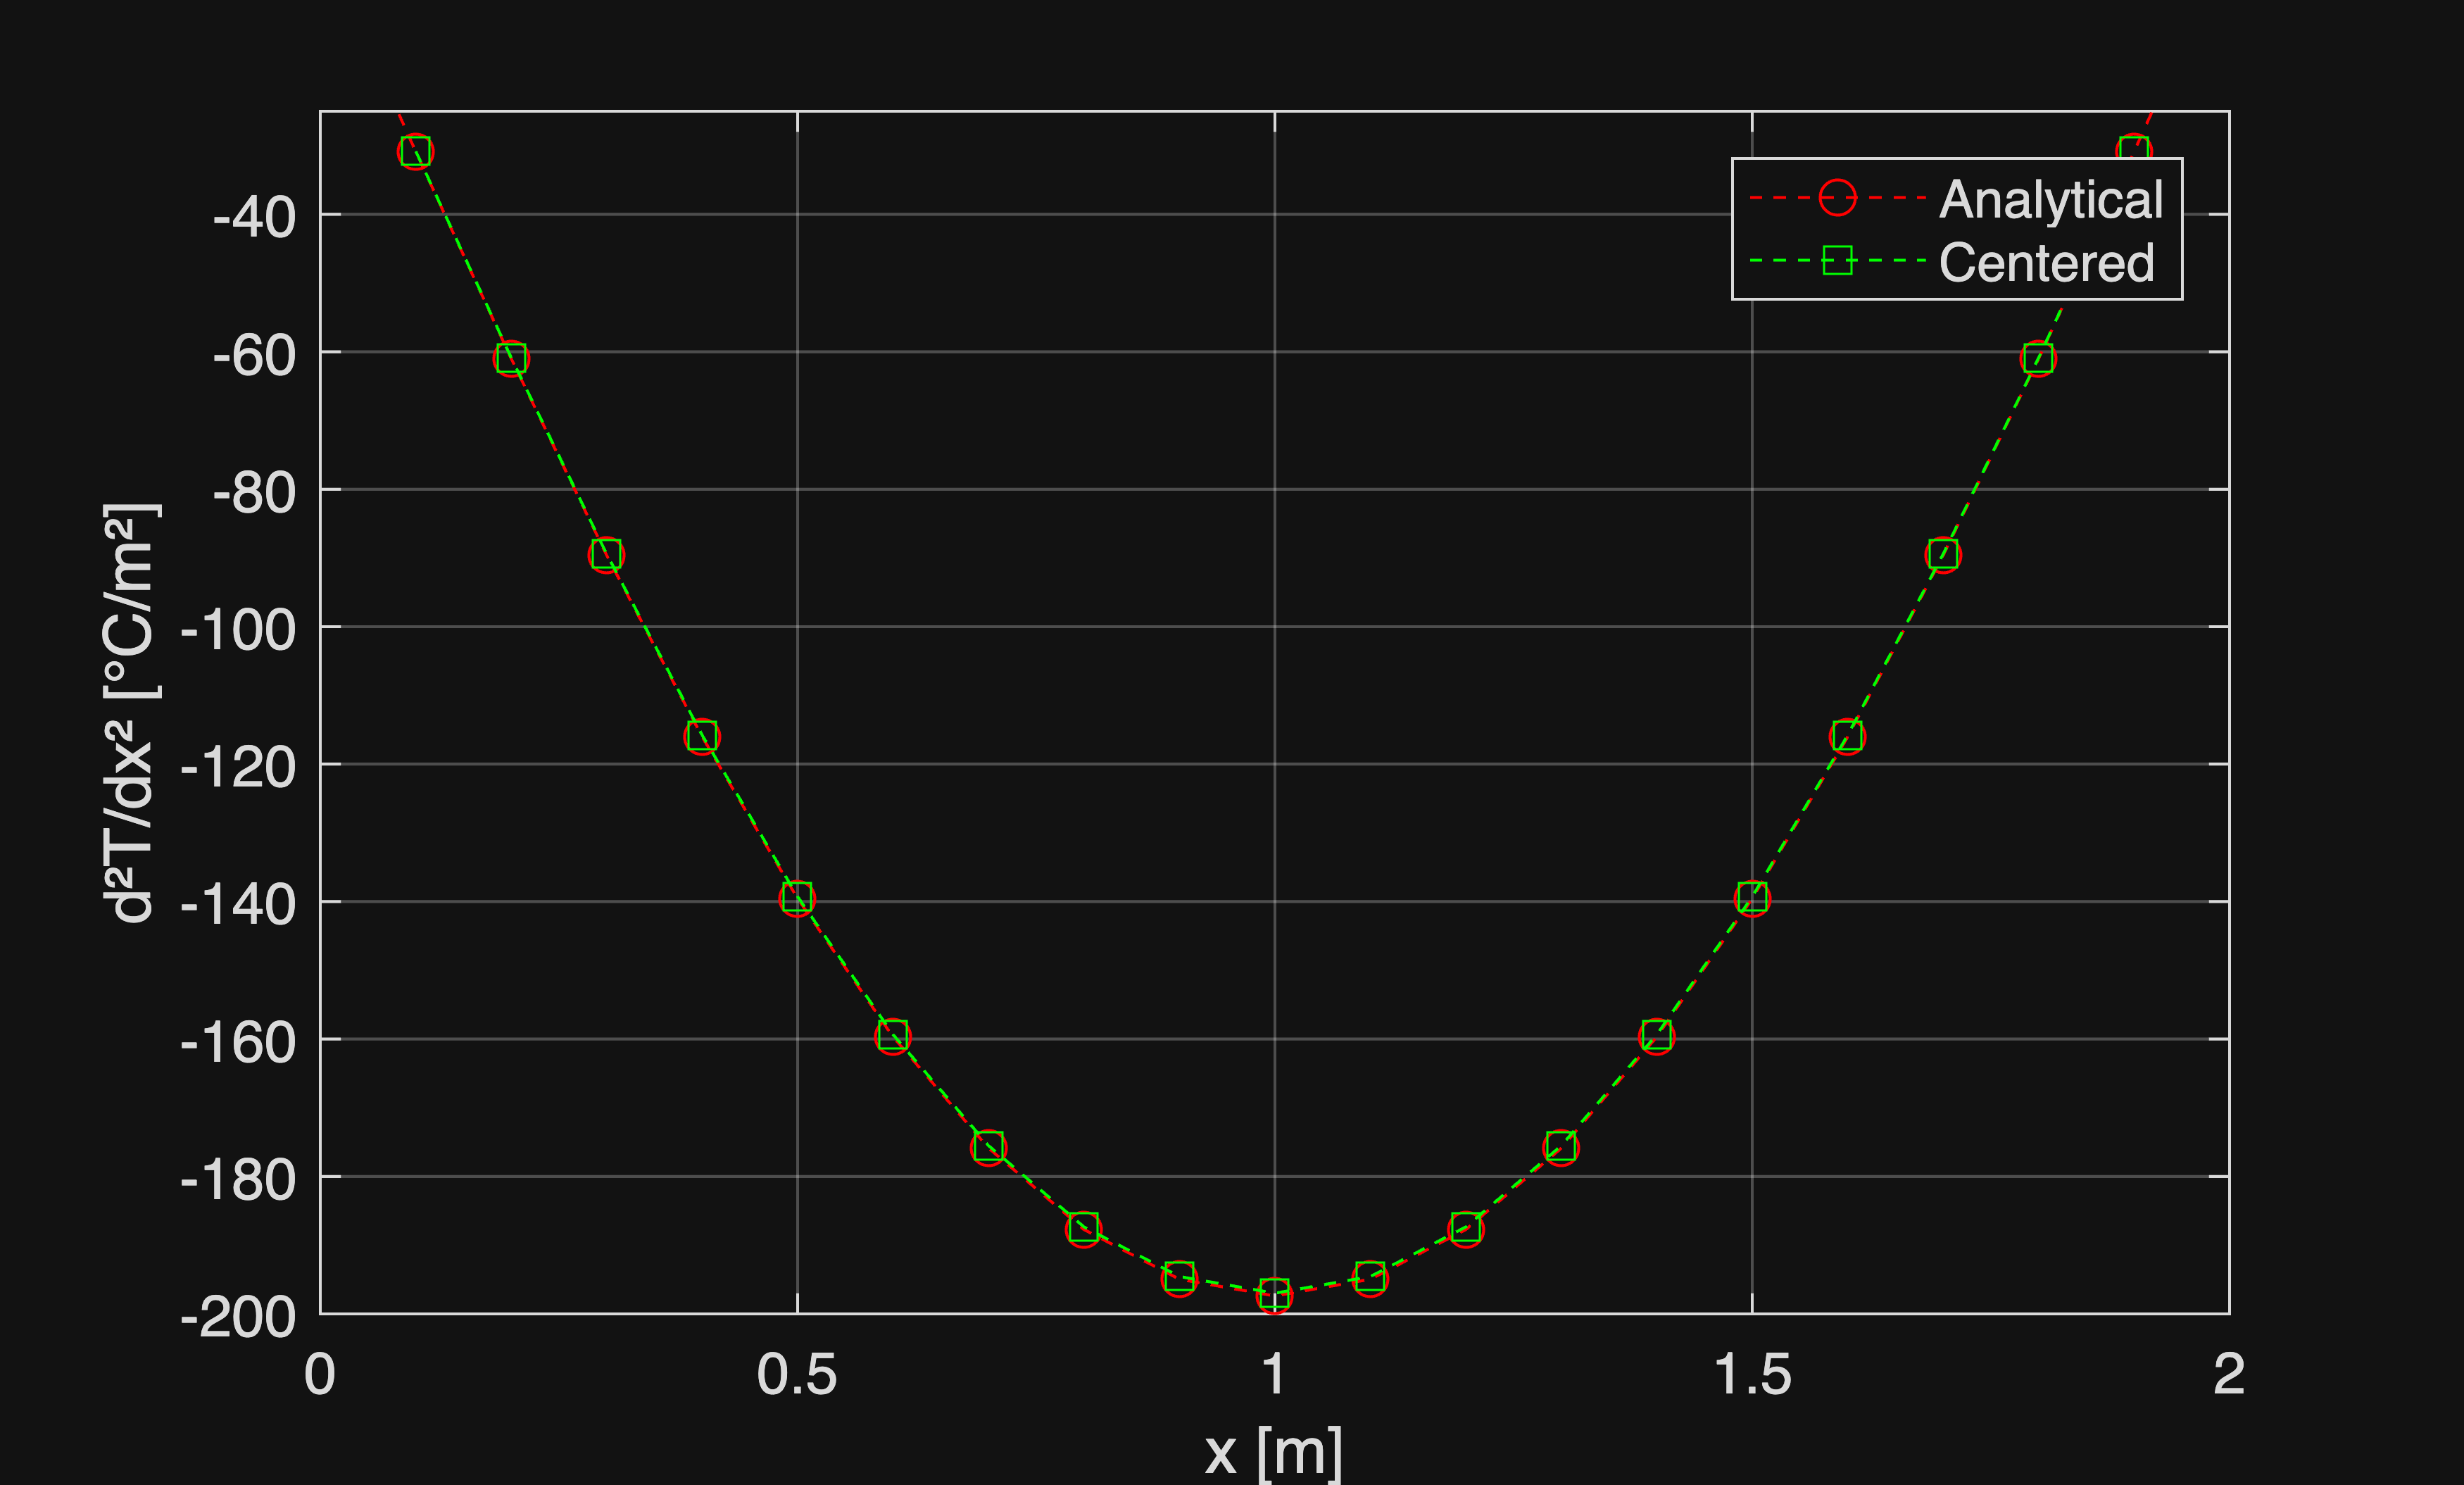

In [20]:

% (γ)
x = 0:h:L;

dT2_anal = -(80*pi^2*sin(pi*x/L))/L^2;

figure
plot(x, dT2_anal, 'ro--', 'DisplayName', 'Analytical');
hold on
plot(x(i), dT2, 'gs--', 'DisplayName', 'Centered');

grid on
legend
xlabel('x [m]')
ylabel('d²T/dx² [°C/m²]')
xlim([0 2])
ylim([-200 -25])
hold off


## Exercise 1.2 (d) — Heat flux and temperature


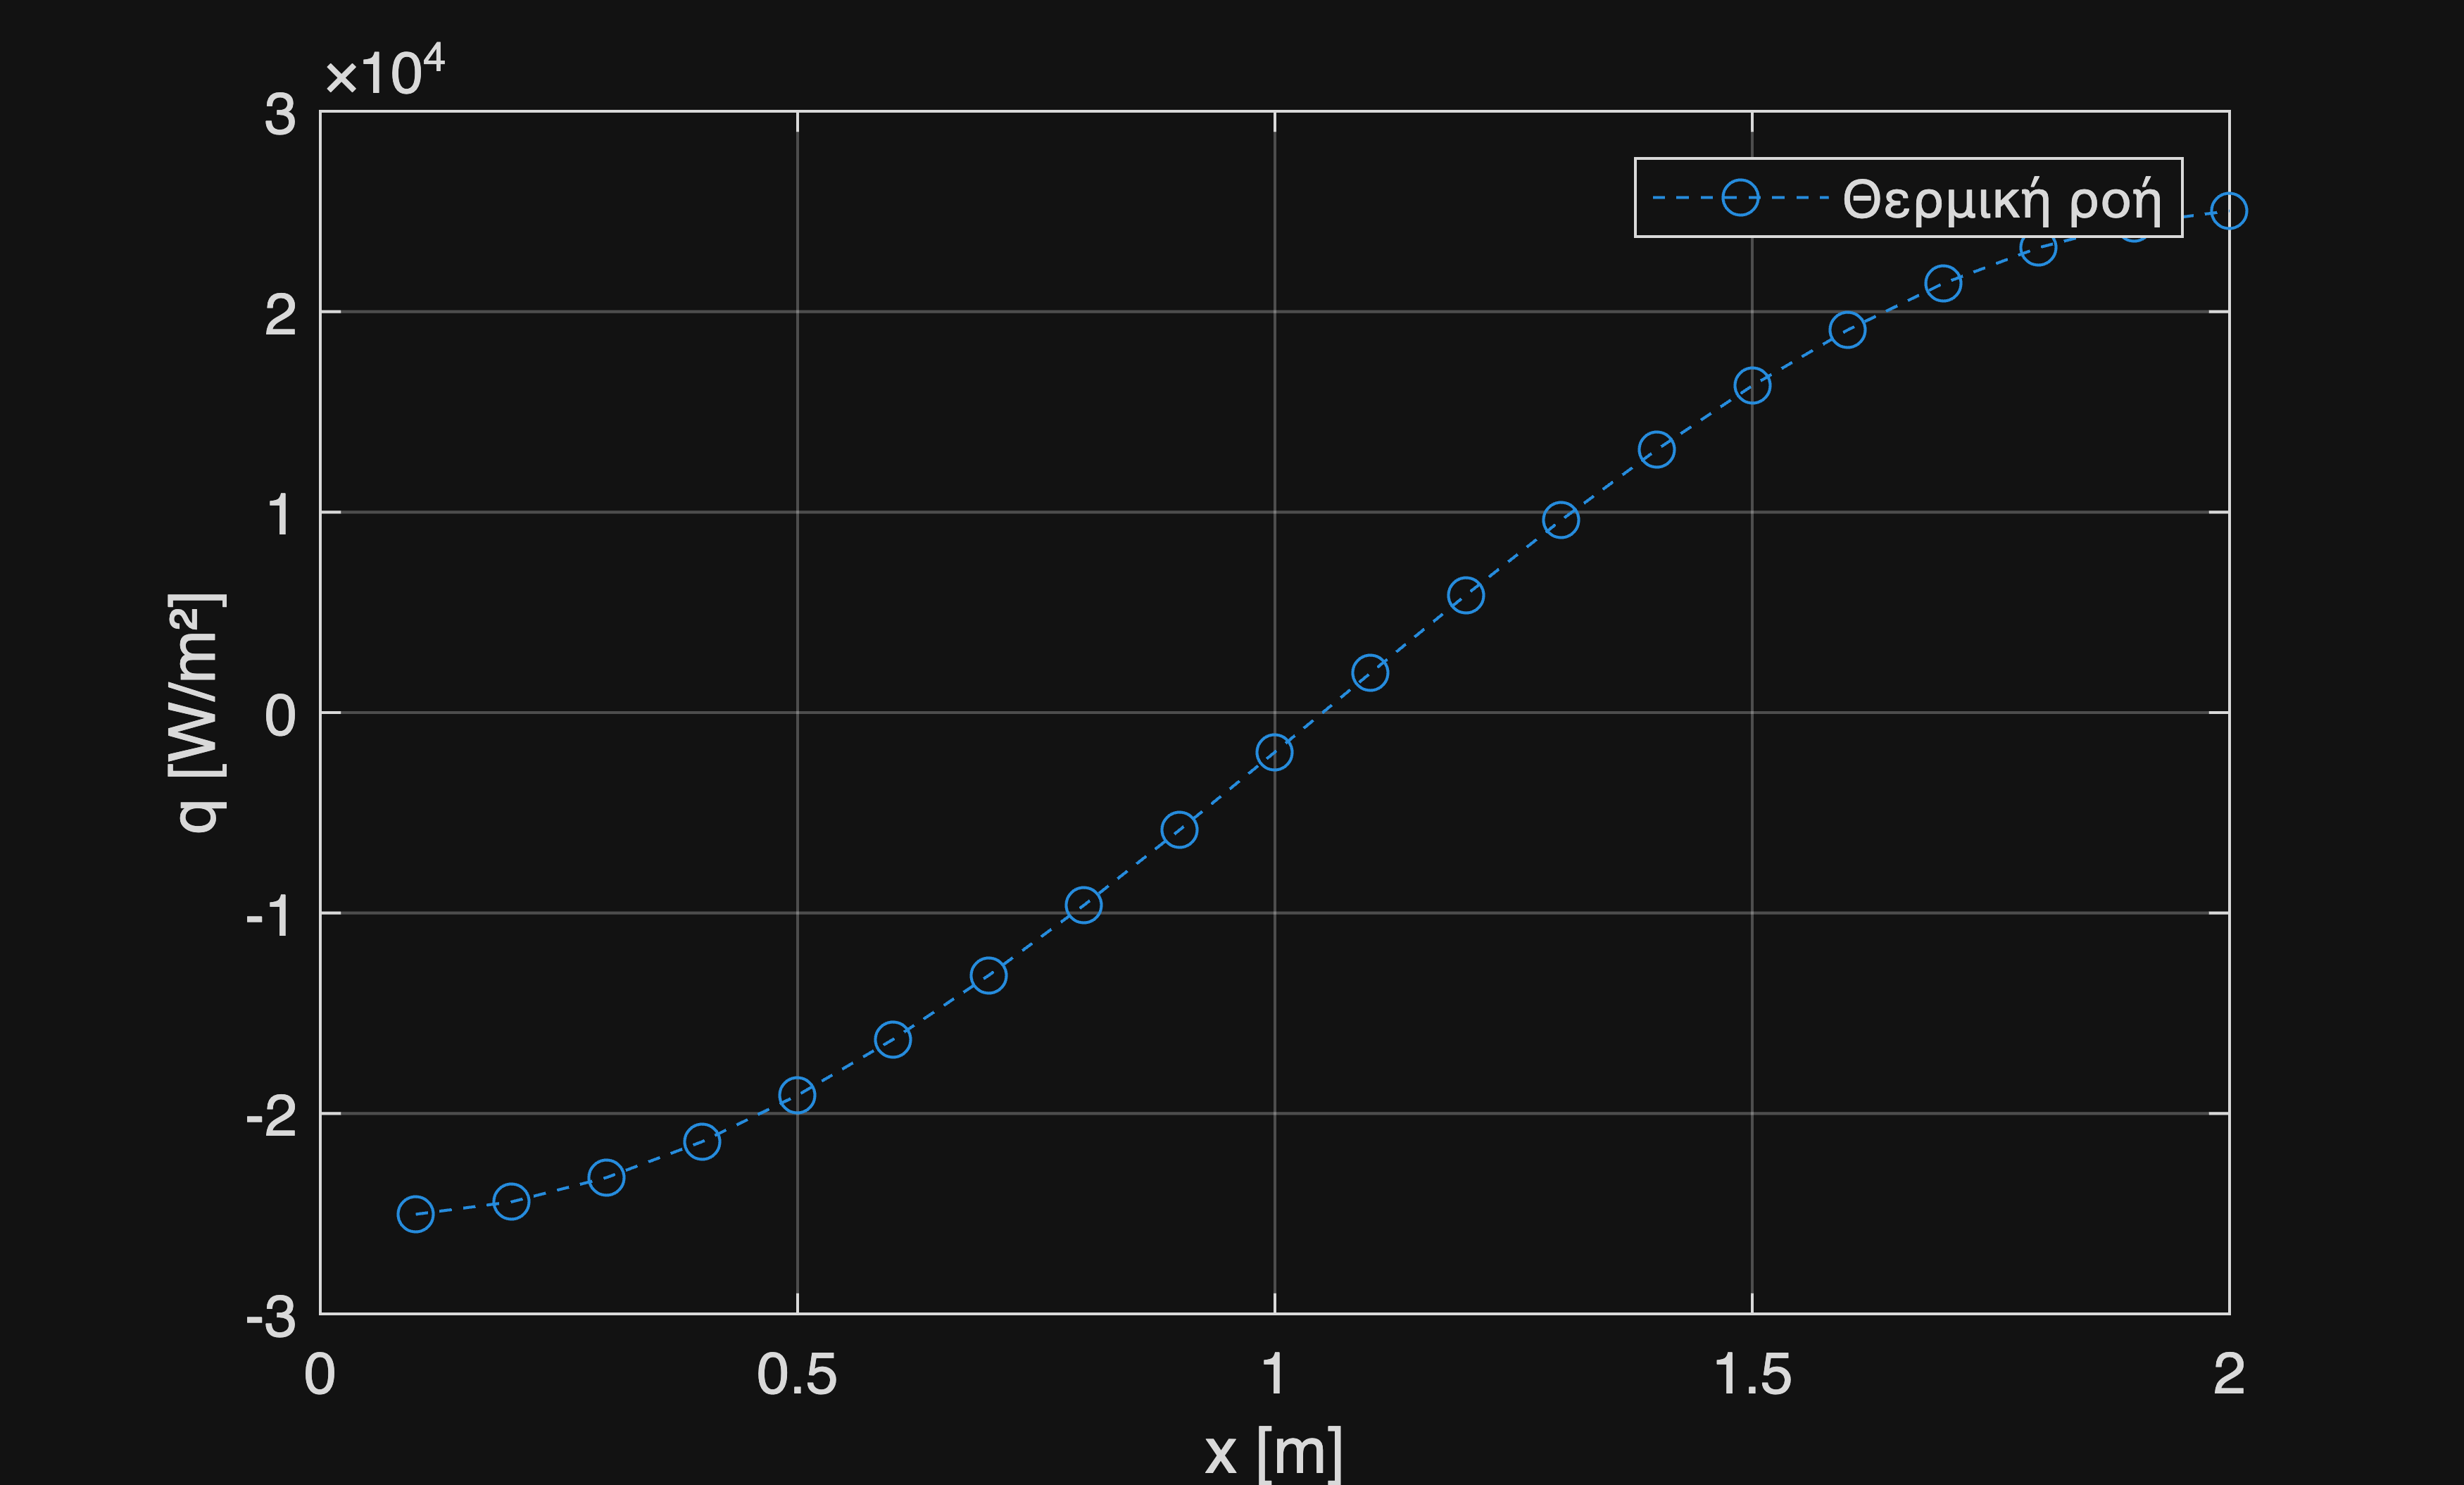

In [21]:

% (δ)
h = 0.1;
L = 2;    % m
k = 200;  % W/(m K)

x = 0:h:L;
T = 20 + 80*sin(pi*x/L);

i = 2:length(T);
dT_b = (T(i) - T(i-1))/h;

q = -k*dT_b;

% Θερμική ροή
figure
plot(x(i), q, 'o--', 'DisplayName', 'Θερμική ροή');

grid on
legend
xlabel('x [m]')
ylabel('q [W/m²]')
xlim([0 2])


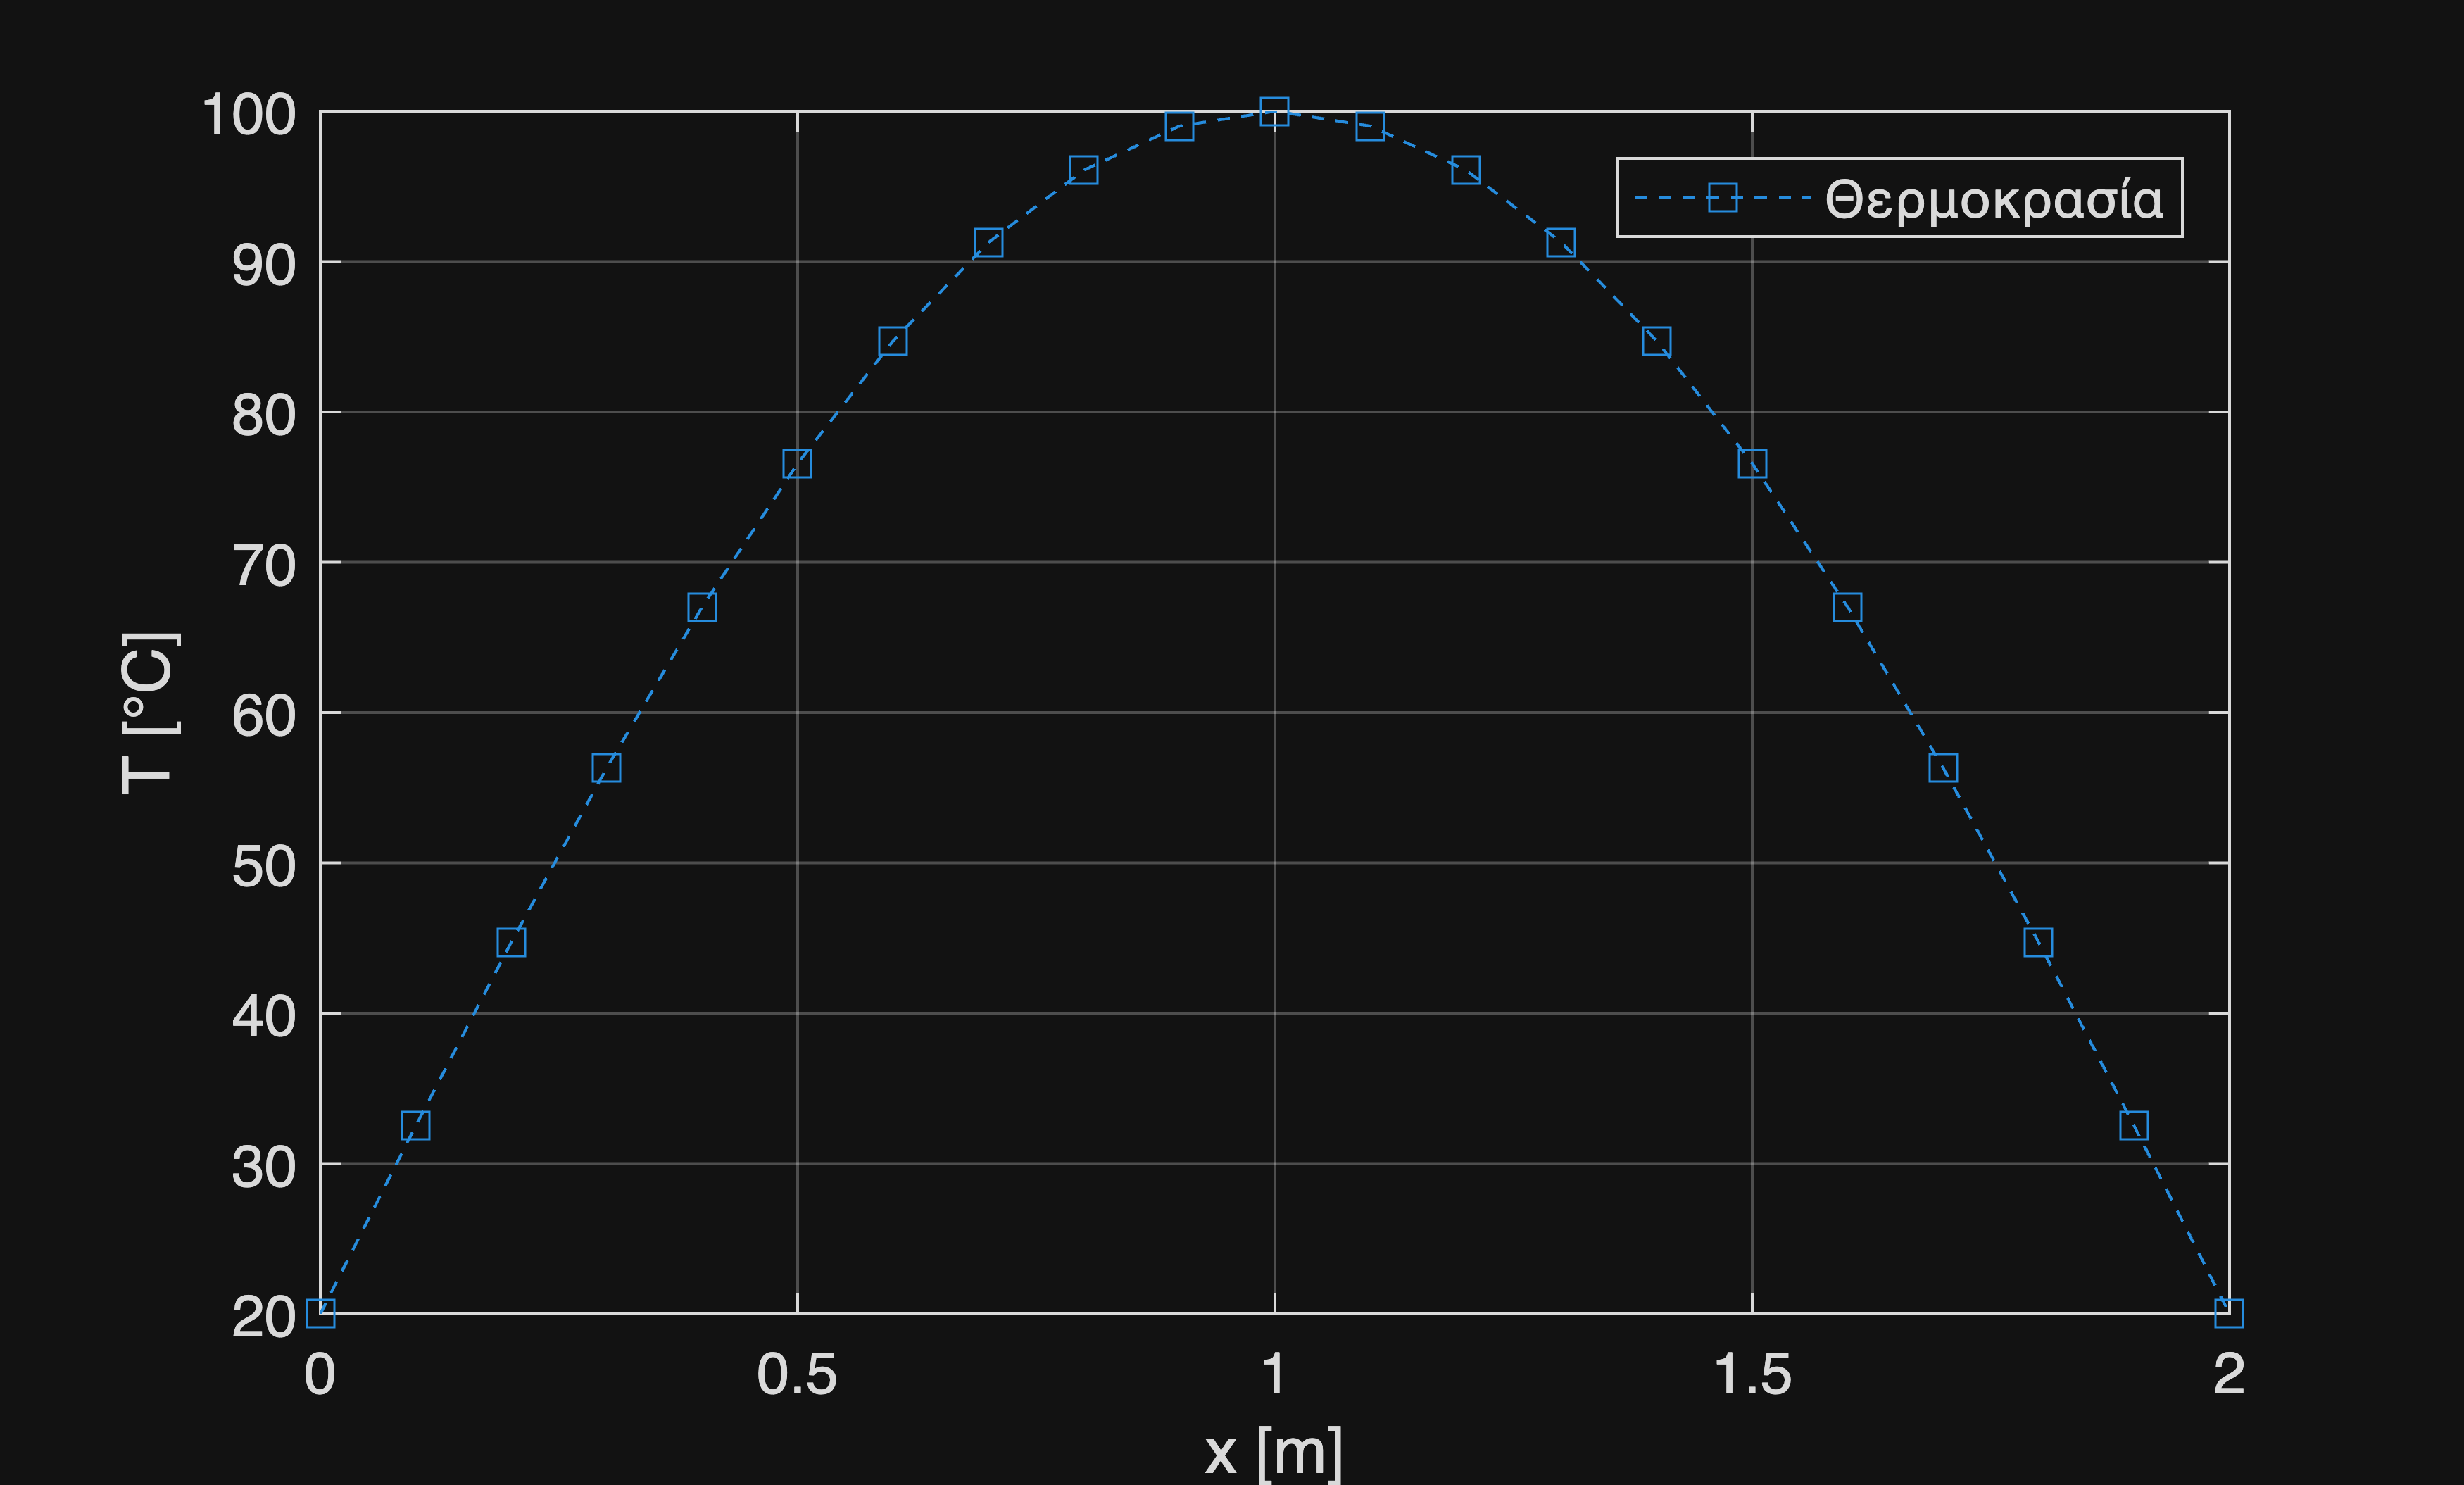

In [22]:

% Θερμοκρασία
figure
plot(x, T, 's--', 'DisplayName', 'Θερμοκρασία');

grid on
legend
xlabel('x [m]')
ylabel('T [°C]')
xlim([0 2])


## Exercise 1.2 — Maximum error for varying h

In [23]:

L = 2;  % m

figure
hold on

for h = [0.2, 0.1, 0.05]

    x = 0:h:L;
    T = 20 + 80*sin(pi*x/L);

    % Central Difference - Second Derivative
    i = 2:length(T)-1;
    d2T = (T(i-1) - 2*T(i) + T(i+1))/h^2;

    % Analytical Second Derivative
    exact = -80*(pi/L)^2*sin(pi*x(i)/L);

    % Maximum Absolute Error
    error = max(abs(d2T - exact));

    fprintf('h = %.2f m, Max Error = %.6f\n', h, error);

    plot(x(i), d2T, '^--', 'DisplayName', sprintf('h = %g', h));

end

h = 0.20 m, Max Error = 1.618153
h = 0.10 m, Max Error = 0.405538
h = 0.05 m, Max Error = 0.101447


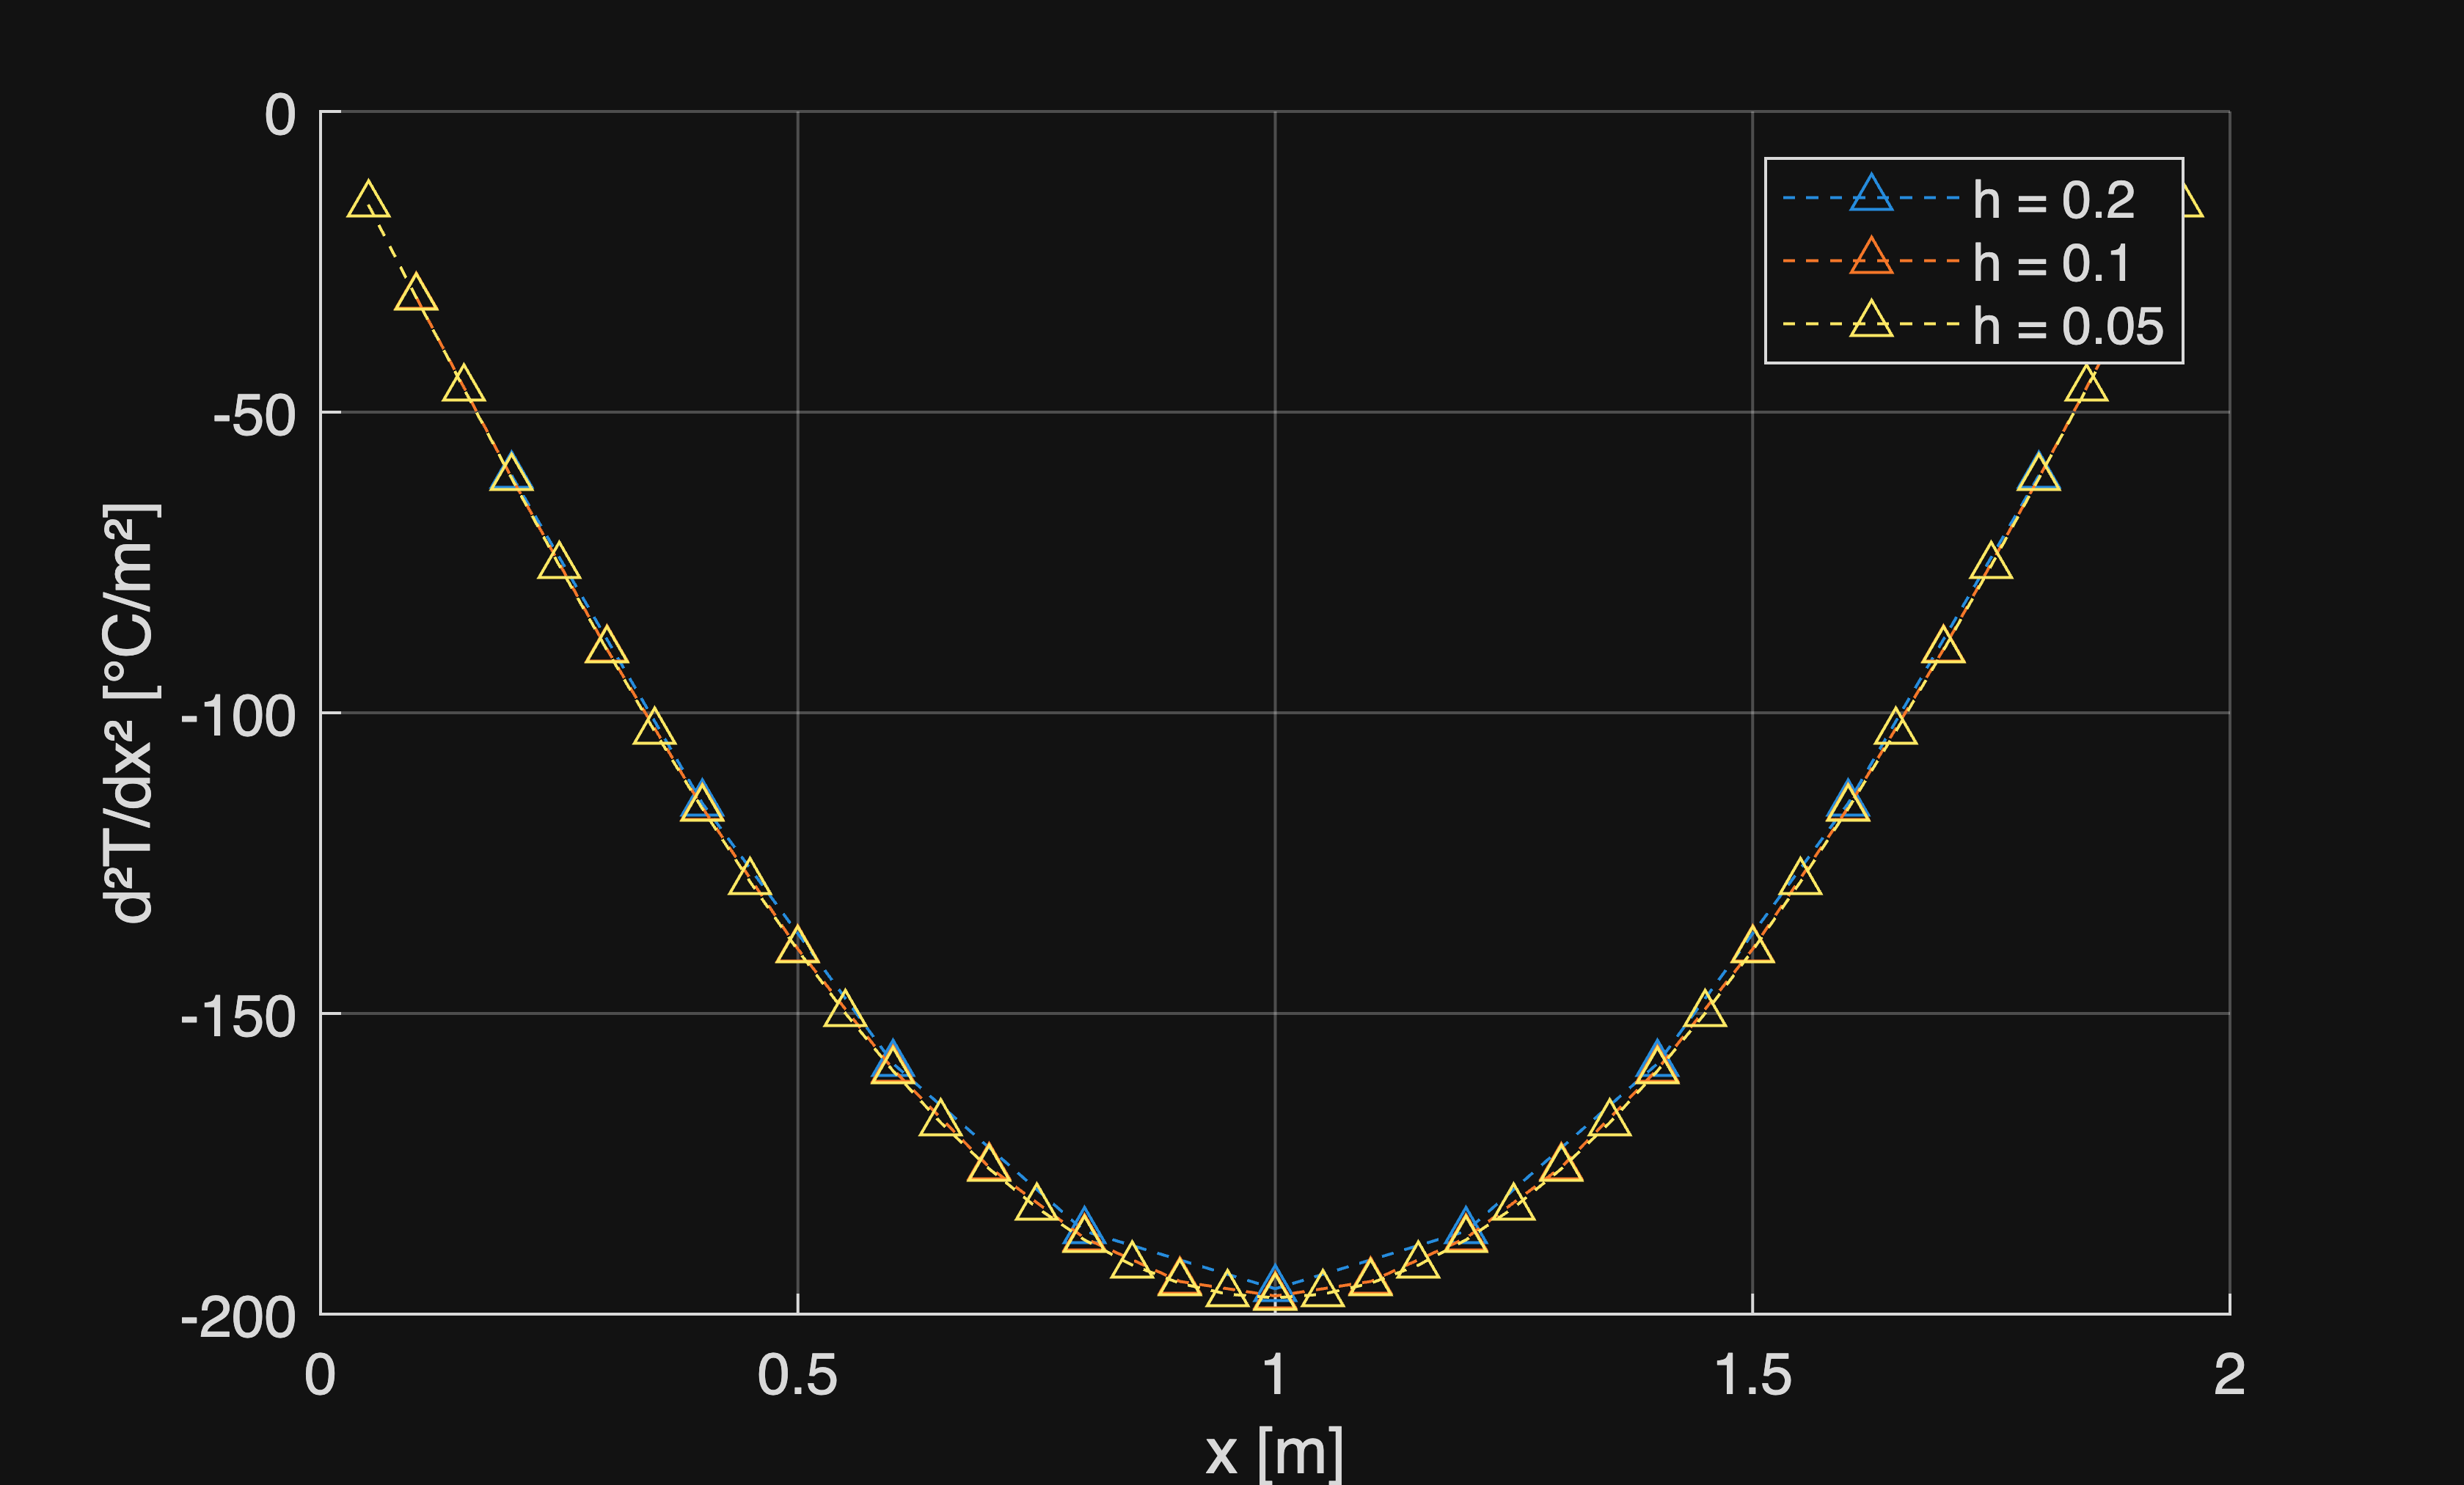

In [24]:

xlabel('x [m]')
ylabel('d²T/dx² [°C/m²]')
legend
grid on
hold off